In [1]:
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt 
import warnings

warnings.filterwarnings('ignore')

In [2]:
data =pd.read_csv('insurance.csv')

In [3]:
data

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [4]:
data.shape

(1338, 7)

In [6]:
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [9]:
data.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [11]:
data.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [12]:
data.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

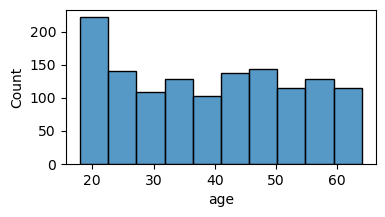

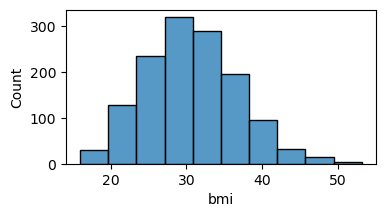

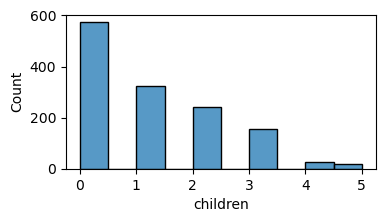

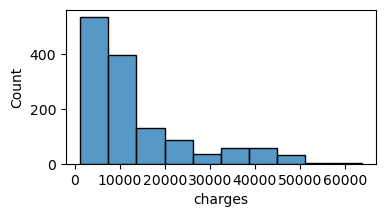

In [15]:
numeric_columns = ['age','bmi','children','charges']
for col in numeric_columns:
    plt.figure(figsize=(4,2))
    sns.histplot(data[col],bins=10)

<Axes: xlabel='children', ylabel='count'>

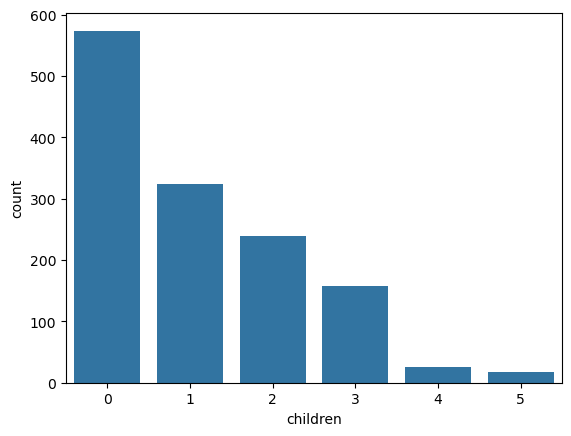

In [24]:
sns.countplot(x=data['children'])



<Axes: xlabel='sex', ylabel='count'>

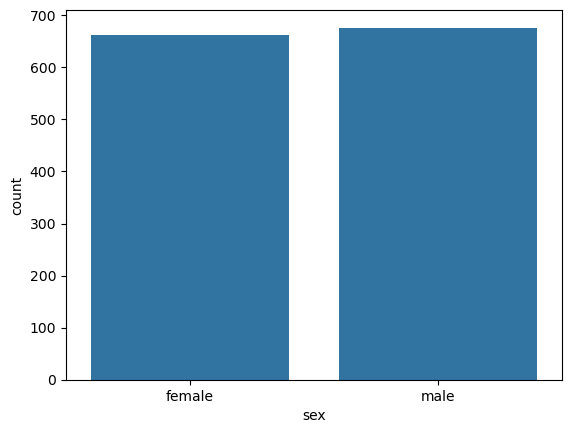

In [22]:
sns.countplot(x=data['sex'])

<Axes: xlabel='region', ylabel='count'>

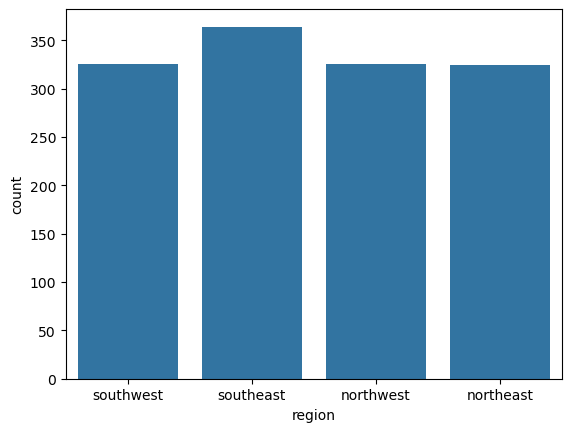

In [23]:
sns.countplot(x=data['region'])

<Axes: xlabel='smoker', ylabel='count'>

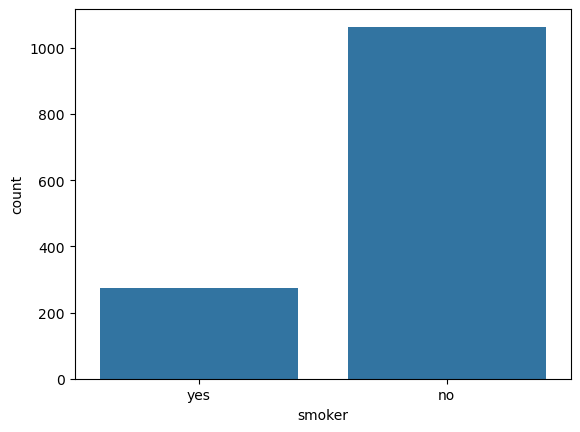

In [25]:
sns.countplot(x=data['smoker'])

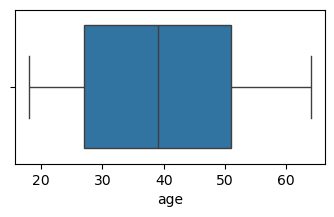

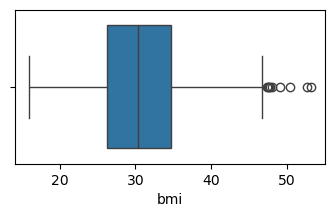

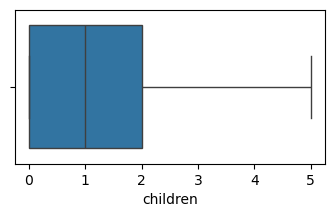

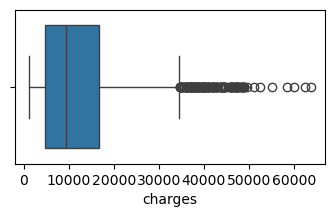

In [29]:
numeric_columns = ['age','bmi','children','charges']
for col in numeric_columns:
    plt.figure(figsize=(4,2))
    sns.boxplot(x=data[col])

<Axes: >

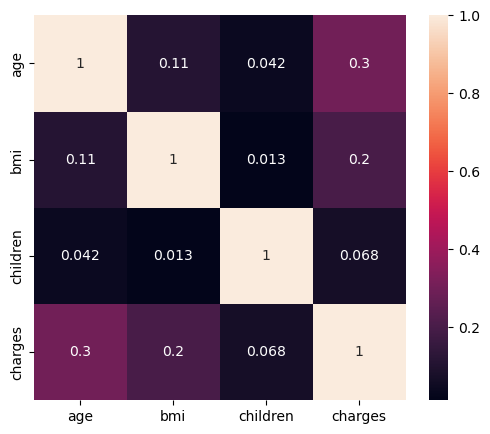

In [35]:
plt.figure(figsize=(6,5))
sns.heatmap(data.corr(numeric_only=True),annot=True)

Data cleaning and preprocessing

In [36]:
df_cleaned=data.copy()

In [37]:
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [38]:
df_cleaned.shape

(1338, 7)

In [39]:
df_cleaned.drop_duplicates(inplace=True)

In [40]:
df_cleaned.shape

(1337, 7)

In [42]:
df_cleaned.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [44]:
df_cleaned.dtypes

age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

In [45]:
df_cleaned['sex'].value_counts()

sex
male      675
female    662
Name: count, dtype: int64

In [60]:
df_cleaned['sex'] = df_cleaned['sex'].map({"male" : 0,"female" : 1})

In [61]:

df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,NaN,27.900,0,yes,southwest,16884.92400
1,18,NaN,33.770,1,no,southeast,1725.55230
2,28,NaN,33.000,3,no,southeast,4449.46200
3,33,NaN,22.705,0,no,northwest,21984.47061
4,32,NaN,28.880,0,no,northwest,3866.85520


In [62]:
df_cleaned['smoker'].value_counts()

smoker
no     1063
yes     274
Name: count, dtype: int64

In [63]:
df_cleaned['smoker'] = df_cleaned['smoker'].map({"no" : 0,"yes" : 1})

In [64]:
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,NaN,27.900,0,1,southwest,16884.92400
1,18,NaN,33.770,1,0,southeast,1725.55230
2,28,NaN,33.000,3,0,southeast,4449.46200
3,33,NaN,22.705,0,0,northwest,21984.47061
4,32,NaN,28.880,0,0,northwest,3866.85520


In [65]:
df_cleaned.rename(columns={
    'sex' :'is_female',
    'smoker': 'is_smoker'
                          },inplace = True)

In [66]:
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,region,charges
0,19,NaN,27.900,0,1,southwest,16884.92400
1,18,NaN,33.770,1,0,southeast,1725.55230
2,28,NaN,33.000,3,0,southeast,4449.46200
3,33,NaN,22.705,0,0,northwest,21984.47061
4,32,NaN,28.880,0,0,northwest,3866.85520
